In [1]:
from scipy.stats import f

n = 8
m = 10  # ступені свободи

q_low = f.ppf(0.025, dfn=m, dfd=n)
q_high = f.ppf(0.975, dfn=m, dfd=n)

print("2.5%:", q_low)
print("97.5%:", q_high)

2.5%: 0.25941071516962244
97.5%: 4.295126960172588


#

# Стат критерій про середнє, при відомій дисперсії
- як рахувати ймов. похибок першого і другого роду

Гіпотеза:  
$H_0$: $\mu=0=\mu_0$  
$H_1$: $\mu\neq 0 =\mu_0$

Тест:

$\zeta_n=|\sqrt{n}\frac{(\hat{\mu}_n-\mu_0)}{\sqrt{\sigma^2}}|$; $(Q^{N(0, 1)}(1 - a/2), \infty)$

In [2]:
import numpy as np
n = 100

mu = 0
mu0 = 0
sigma = 1

In [3]:
x = np.random.normal(mu0, sigma, size=n)
x[:3]

array([-1.98487852,  0.84880796, -0.16806284])

In [4]:
x.mean()

np.float64(-0.025271861640923588)

In [5]:
# test

def stat(x, mu0):
    n = len(x)
    return np.abs(n ** 0.5 * (x.mean() - mu0) / sigma)


In [6]:
from scipy.stats import norm
a = 0.05
kappa = norm(0, 1).ppf(1 - a / 2)

In [7]:
print(stat(x, mu0), kappa)
print("Приймаємо гіпотезу Н{}".format(int(stat(x, mu0) > kappa)))

0.2527186164092359 1.959963984540054
Приймаємо гіпотезу Н0


In [8]:
# Under H0
from tqdm import tqdm
H = 10000

a = 0.05
kappa = norm(0, 1).ppf(1 - a / 2)

first_error_rate = []

for n in tqdm(range(200, 5001, 200)):
    hyps = []
    for _ in (range(H)):
        x = np.random.normal(mu0, sigma, size=n)
        hyps.append(int(stat(x, mu0) > kappa))
    
    hyps = np.array(hyps)
    first_error_rate.append((hyps == 1).mean())

100%|██████████████████████████████████████████████████████████████████████████████████| 25/25 [00:33<00:00,  1.33s/it]


In [9]:
(hyps == 1).mean(), a

(np.float64(0.0477), 0.05)

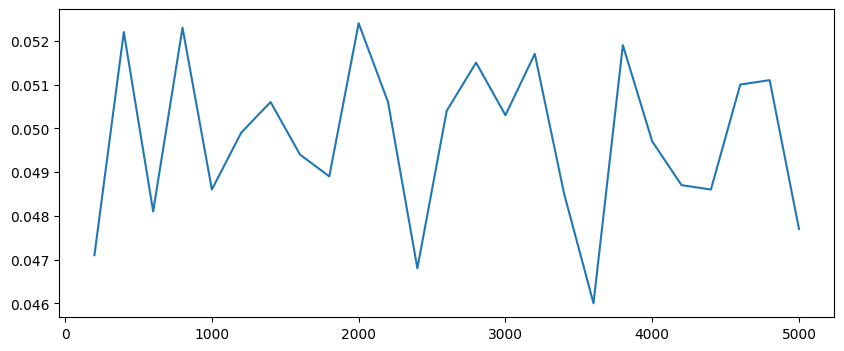

In [12]:
from matplotlib import pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(range(200, 5001, 200), first_error_rate)

In [ ]:
import numpy as np
n = 100

mu = 1
sigma = 1

mu0 = 0


In [21]:
# Under H1
x = np.random.normal(mu, sigma, size=n)

In [22]:
print(stat(x, mu0), kappa)
print("Приймаємо гіпотезу Н{}".format(int(stat(x, mu0) > kappa)))

2.3134409307838273 1.959963984540054
Приймаємо гіпотезу Н1


In [48]:
# Under H1
from tqdm import tqdm
H = 400

a = 0.05
kappa = norm(0, 1).ppf(1 - a / 2)



mu = 0.1
sigma = 1
rates = []
for mu in tqdm(np.linspace(-1, 1, 101)):
    second_error_rate = []
    for n in (range(10, 1001, 10)):
        hyps = []
        for _ in (range(H)):
            x = np.random.normal(mu, sigma, size=n)
            hyps.append(int(stat(x, mu0) > kappa))
        
        hyps = np.array(hyps)
        second_error_rate.append((hyps == 0).mean())
    rates.append(np.array(second_error_rate))

rates = np.array(rates)

100%|████████████████████████████████████████████████████████████████████████████████| 101/101 [01:59<00:00,  1.19s/it]


In [49]:
rates.shape

(101, 100)

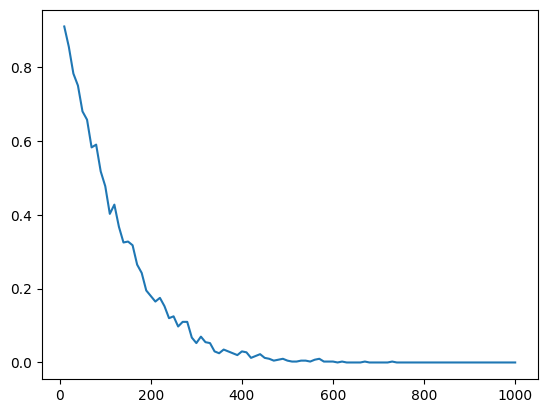

In [54]:
plt.plot(range(10, 1001, 10), rates[60])

In [52]:
# np.linspace(-1, 1, 101)[50]

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
C:\Users\v.miroshnychenko\AppData\Local\Temp\ipykernel_31672\1214723366.py:4: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('\mu')


Text(0.5, 1.0, '2-nd error rate')

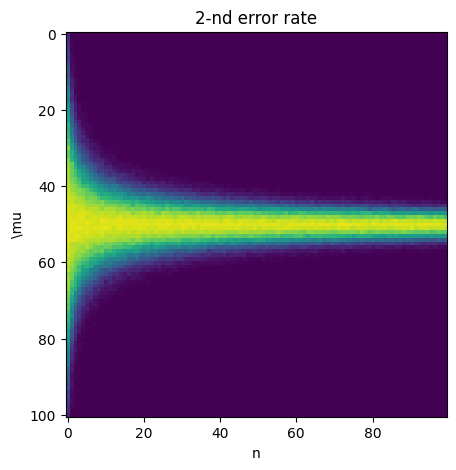

In [57]:
plt.figure(figsize=(5, 5))
plt.imshow(rates, vmin=0, vmax=1)
plt.xlabel('n')
plt.ylabel('\mu')
plt.title("2-nd error rate")


In [47]:
rates[51]

array([0.96, 0.96, 0.97, 0.95, 0.93, 0.92, 0.97, 0.97, 0.95, 0.96, 0.94,
       0.95, 0.96, 0.93, 0.93, 0.93, 0.94, 0.95, 0.91, 0.91, 0.97, 0.94,
       0.92, 0.9 , 0.94, 0.96, 0.94, 0.96, 0.96, 0.91, 0.95, 0.94, 0.95,
       0.97, 0.95, 0.91, 0.9 , 0.98, 0.96, 0.94, 0.91, 0.91, 0.95, 0.93,
       0.86, 0.92, 0.93, 0.89, 0.9 , 0.91, 0.92, 0.92, 0.93, 0.93, 0.9 ,
       0.95, 0.92, 0.91, 0.91, 0.98, 0.95, 0.92, 0.89, 0.94, 0.9 , 0.91,
       0.93, 0.93, 0.93, 0.86, 0.86, 0.92, 0.88, 0.95, 0.95, 0.93, 0.93,
       0.91, 0.88, 0.88, 0.9 , 0.93, 0.91, 0.92, 0.97, 0.95, 0.96, 0.87,
       0.9 , 0.91, 0.87, 0.93, 0.92, 0.96, 0.87, 0.92, 0.94, 0.93, 0.9 ,
       0.91])

# Задача 2 Стат критерій про середнє, при невідомій дисперсії
- як рахувати ймов. похибок першого і другого роду

Гіпотеза:  
$H_0$: $\mu=0=\mu_0$  
$H_1$: $\mu\neq 0 =\mu_0$

Тест:

$\zeta_n=|\sqrt{n}\frac{(\hat{\mu}_n-\mu_0)}{\sqrt{S^2_n}}|$; $(Q^{T_{n-1}}(1 - a/2), \infty)$

In [60]:
# test

def stat2(x, mu0):
    n = len(x)
    return np.abs(n ** 0.5 * (x.mean() - mu0) / x.std())


In [64]:
# Under H0
from scipy.stats import t
from tqdm import tqdm
H = 10000
sigma = 1

mu0 = 0

a = 0.05



first_error_rate = []

for n in tqdm(range(200, 5001, 200)):
# for n in tqdm([100]):
    kappa = t.ppf(1 - a / 2, n - 1)
    hyps = []
    for _ in (range(H)):
        x = np.random.normal(mu0, sigma, size=n)
        hyps.append(int(stat2(x, mu0) > kappa))
    
    hyps = np.array(hyps)
    first_error_rate.append((hyps == 1).mean())

100%|██████████████████████████████████████████████████████████████████████████████████| 25/25 [00:30<00:00,  1.20s/it]


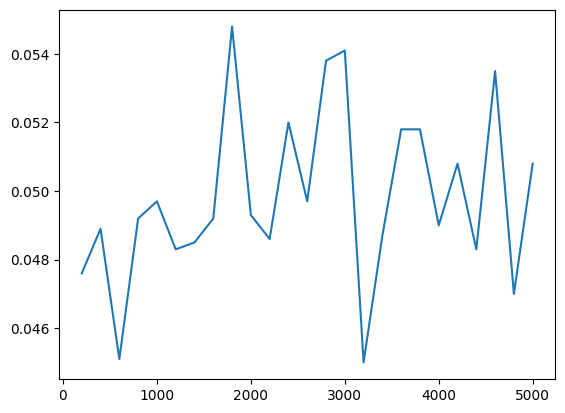

In [65]:
plt.plot(range(200, 5001, 200), first_error_rate)

Стат тест із асимптотичним рівнем 5%  
$\zeta_n=|\sqrt{n}\frac{(\hat{\mu}_n-\mu_0)}{\sqrt{S^2_n}}|$; $(Q^{N(0, 1)}(1 - a/2), \infty)$

In [68]:
# Under H0
from scipy.stats import t
from tqdm import tqdm
H = 10000
sigma = 1

mu0 = 0

a = 0.05



first_error_rate = []

# for n in tqdm(range(200, 5001, 200)):
for n in tqdm(range(2, 101, 1)):
    # kappa = t.ppf(1 - a / 2, n - 1)
    kappa = norm(0, 1).ppf(1 - a / 2)
    hyps = []
    for _ in (range(H)):
        x = np.random.normal(mu0, sigma, size=n)
        hyps.append(int(stat2(x, mu0) > kappa))
    
    hyps = np.array(hyps)
    first_error_rate.append((hyps == 1).mean())

100%|██████████████████████████████████████████████████████████████████████████████████| 99/99 [00:27<00:00,  3.55it/s]


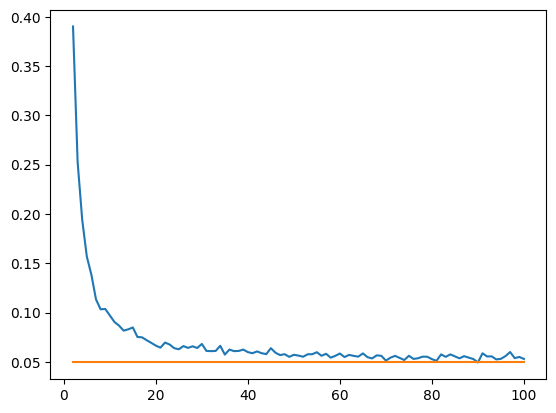

In [70]:
plt.plot(range(2, 101, 1), first_error_rate)
plt.plot([2, 100], [0.05, 0.05])

In [71]:
# Under H1
from tqdm import tqdm
H = 50

a = 0.05



mu = 0.1
sigma = 1
rates = []
for sigma in tqdm(np.linspace(0.1, 2, 101)):
    second_error_rate = []
    for n in (range(10, 1001, 10)):
        kappa = t.ppf(1 - a / 2, n - 1)
        hyps = []
        for _ in (range(H)):
            x = np.random.normal(mu, sigma, size=n)
            hyps.append(int(stat2(x, mu0) > kappa))
        
        hyps = np.array(hyps)
        second_error_rate.append((hyps == 0).mean())
    rates.append(np.array(second_error_rate))

rates = np.array(rates)

100%|████████████████████████████████████████████████████████████████████████████████| 101/101 [00:23<00:00,  4.26it/s]


<>:4: SyntaxWarning: invalid escape sequence '\s'
<>:4: SyntaxWarning: invalid escape sequence '\s'
C:\Users\v.miroshnychenko\AppData\Local\Temp\ipykernel_31672\3553932322.py:4: SyntaxWarning: invalid escape sequence '\s'
  plt.ylabel('\sigma')


Text(0.5, 1.0, '2-nd error rate')

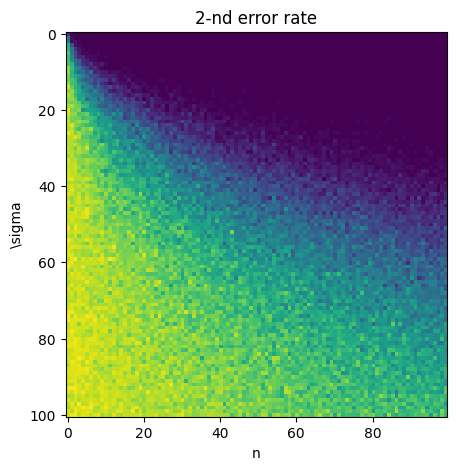

In [72]:
plt.figure(figsize=(5, 5))
plt.imshow(rates, vmin=0, vmax=1)
plt.xlabel('n')
plt.ylabel('\sigma')
plt.title("2-nd error rate")
